# 07 - Stacking: Random Forest + XGBoost + Linear Regression

## 1. Objective

Notebooks 05 and 06 trained the two ensembles that combine many trees of the **same** kind: bagging (Random Forest) and boosting (XGBoost). This notebook builds the third type of ensemble, **stacking**, which combines **different** models:

| Notebook | Ensemble type | Model | How the predictions are combined |
|---|---|---|---|
| 05 | Bagging | Random Forest | average of many independent trees |
| 06 | Boosting | XGBoost | sum of trees trained one after another |
| **07 (this notebook)** | **Stacking** | **Random Forest + XGBoost + Linear Regression** | a **meta-model** learns how to combine the three predictions |
| 08 | Comparison | all | bagging vs boosting vs stacking on the same test rows, with diagnostics |

**Steps in this notebook**
1. **Base predictions (sections 2-5):** for every year 2016-2023, train the three base models on earlier years only and predict that year.
2. **Validation (sections 6-7):** choose the meta-model (Random Forest or Linear Regression) on 2023. The test set is **not used** in these sections.
3. **Final test (section 8):** refit the meta-model on 2016-2023 and score the stack **once** on the test set (2024-2026), next to persistence.
4. **Explain and save (sections 9-10):** what the meta-model relied on, then save the models and results for notebook 08 and the dashboard.

The same 11 features, the same leakage check and the same chronological split as notebooks 04-06 are used.

In [1]:
import json
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import xgboost
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
from xgboost import XGBRegressor

TRAIN_PATH = Path("../dataset/processed/train.csv")
TEST_PATH = Path("../dataset/processed/test.csv")

# saved in notebook 05 (bagging) and notebook 06 (boosting)
RF_RESULTS_PATH = Path("../models/05_random_forest_results.json")
RF_MODEL_PATH = Path("../models/05_final_random_forest_model.joblib")
XGB_RESULTS_PATH = Path("../models/06_xgboost_results.json")
XGB_MODEL_PATH = Path("../models/06_final_xgboost_model.json")

# saved by this notebook
RESULTS_PATH = Path("../models/07_stacking_results.json")
LR_MODEL_PATH = Path("../models/07_final_linear_regression_model.joblib")
META_MODEL_PATH = Path("../models/07_stacking_meta_model.joblib")

rf_info = json.loads(RF_RESULTS_PATH.read_text())
xgb_info = json.loads(XGB_RESULTS_PATH.read_text())
for key in ["features", "target", "random_state", "validation_year"]:
    assert rf_info[key] == xgb_info[key], key

FEATURES = rf_info["features"]
TARGET = rf_info["target"]
RANDOM_STATE = rf_info["random_state"]
VALIDATION_YEAR = rf_info["validation_year"]   # 2023
RF_PARAMS = rf_info["params"]                  # chosen in notebook 05
XGB_PARAMS = xgb_info["params"]                # chosen in notebook 06
TREE_MAX_DEPTH = 5                             # best Decision Tree setting from notebook 04
FIRST_STACK_YEAR = 2016                        # first year with out-of-sample base predictions

# the meta-model always receives the three base predictions in this column order
BASE_MODELS = ["Random Forest", "XGBoost", "Linear Regression"]

print("Random Forest settings:", RF_PARAMS)
print("XGBoost settings:      ", XGB_PARAMS)

# chart colours (the same in notebooks 04-08)
COLORS = {"Persistence": "#898781", "Decision Tree": "#eb6834", "Linear Regression": "#8f6bb3",
          "Random Forest": "#2a78d6", "XGBoost": "#1baf7a", "Stacking": "#d6457f"}
INK, GRID = "#0b0b0b", "#e4e3df"

Random Forest settings: {'n_estimators': 200, 'min_samples_leaf': 10}
XGBoost settings:       {'n_estimators': 400, 'max_depth': 2, 'learning_rate': 0.05}


## 2. Load the data, remove leaky rows

The same steps as notebooks 05 and 06, repeated so this notebook runs on its own:
1. Load `train.csv` (target weeks up to 2023 only). The test set is loaded later, in section 8.
2. **Leakage check:** remove rows whose current week was interpolated (`is_imputed`). Their value was calculated from next week's cases, i.e. from the target. Also remove rows whose target was interpolated (`target_imputed`).

The chronological split is done year by year in section 5.

In [2]:
data = pd.read_csv(TRAIN_PATH, parse_dates=["start_date", "target_date"])
assert data["target_date"].max() <= pd.Timestamp("2023-12-31")  # no test weeks
assert data[FEATURES + [TARGET]].notna().all().all()
assert TARGET not in FEATURES and "target_log_next" not in FEATURES

# leakage check: interpolated weeks
leaky_or_estimated = data["is_imputed"] | data["target_imputed"]
data = data[~leaky_or_estimated].reset_index(drop=True)
print("removed interpolated rows:", leaky_or_estimated.sum())

target_year = data["target_date"].dt.year
print("rows:", len(data), "| target weeks", data["target_date"].min().date(), "to", data["target_date"].max().date())

removed interpolated rows: 52
rows: 21684 | target weeks 2007-12-29 to 2023-12-30


## 3. What is stacking?

**Stacking** (stacked generalisation, Wolpert, 1992) combines **different kinds of model**. It has two levels:

```
                         11 input features
              ┌──────────────────┼──────────────────┐
              ▼                  ▼                  ▼
        Random Forest         XGBoost        Linear Regression      level 0: base models
              │                  │                  │
              └──────────────────┼──────────────────┘
                                 ▼
               3 predictions for every district-week
                                 ▼
                            meta-model                              level 1
                                 ▼
                     final prediction (clipped at 0)
```

1. **Base models** (level 0) each predict next week's cases from the 11 features.
2. A **meta-model** (level 1) takes the three predictions as its inputs and learns **how much to trust each one**. For example, it may learn "mostly follow the Random Forest, but add a little of the Linear Regression".

The idea is that different models make **different mistakes**. Bagging and boosting combine many trees of one kind; stacking can also combine a tree ensemble with a linear model.

**Bagging vs boosting vs stacking**

| | Bagging | Boosting | Stacking |
|---|---|---|---|
| Base models | many models of the **same** type (here: trees) | many models of the **same** type (here: small trees) | a few models of **different** types |
| How they are trained | **independently, in parallel**, each on a bootstrap sample | **sequentially**, each one fitted to the errors of the models before it | base models first, then a **meta-model** trained on their predictions |
| How predictions are combined | **average** (regression) or majority vote (classification) | **weighted sum** of all models | **learned** by the meta-model |
| Mainly reduces | **variance** (overfitting) | **bias** (underfitting) | can reduce both, if the base models make different errors |
| Main risk | cannot predict beyond the range of past values | can overfit rare patterns; needs careful settings | **leakage** if the meta-model is trained on predictions for rows the base models were trained on; more complex |
| Example in this project | Random Forest (notebook 05) | XGBoost (notebook 06) | this notebook |

## 4. The base models

| Base model | Settings | Where they come from |
|---|---|---|
| Random Forest | 200 trees, `min_samples_leaf = 10` | chosen on 2023 in notebook 05 (`05_random_forest_results.json`) |
| XGBoost | 400 rounds, `max_depth = 2`, `learning_rate = 0.05`, predictions clipped at 0 | chosen on 2023 in notebook 06 (`06_xgboost_results.json`) |
| Linear Regression | `LinearRegression()` (no settings) | multiple linear regression from notebook 04 |

No base-model setting is changed here. The Random Forest predicts in a single thread (`n_jobs=1`) so its predictions are exactly repeatable (see notebook 05). The Linear Regression is used without clipping, as in notebook 04.

In [3]:
def make_base_models():
    """Three new, untrained base models with the settings from notebooks 04-06."""
    return {
        "Random Forest": RandomForestRegressor(**RF_PARAMS, random_state=RANDOM_STATE, n_jobs=-1),
        "XGBoost": XGBRegressor(**XGB_PARAMS, random_state=RANDOM_STATE, n_jobs=-1),
        "Linear Regression": LinearRegression(),
    }


def base_predictions(models, X):
    """The three base predictions as a table, always in the column order BASE_MODELS."""
    return pd.DataFrame({
        "Random Forest": models["Random Forest"].predict(X),
        "XGBoost": np.clip(models["XGBoost"].predict(X), 0, None),   # no negative case counts
        "Linear Regression": models["Linear Regression"].predict(X),
    }, index=X.index)[BASE_MODELS]


def evaluate(actual, predicted):
    return {"MAE": mean_absolute_error(actual, predicted), "RMSE": root_mean_squared_error(actual, predicted)}

## 5. Walk-forward base predictions, 2016-2023

The meta-model must learn from base predictions for weeks the base models have **not** seen. A Random Forest fits its own training rows very closely, so predictions on its training rows would look far too good, and the meta-model would learn to trust it too much. This is a form of **data leakage**.

So the base predictions are made **walk-forward**, one year at a time:

| Predicted year | Base models trained on target weeks |
|---|---|
| 2016 | 2007-2015 |
| 2017 | 2007-2016 |
| ... | ... |
| 2023 | 2007-2022 |

Every prediction is made by base models that were trained on **earlier years only**. This gives 8 years of honest ("out-of-sample") predictions to train and choose the meta-model. 2016 is the first year, so the earliest base models still have 8 years of training data.

*Note:* this is the same idea as scikit-learn's `StackingRegressor`, which makes the base predictions with cross-validation, but here it is done **in time order**, so no future weeks leak into the training of the base models.

In [4]:
stack_parts = []
year_rows = []
for year in range(FIRST_STACK_YEAR, VALIDATION_YEAR + 1):
    past = data[target_year < year]          # earlier years only
    this_year = data[target_year == year]

    models = make_base_models()
    for model in models.values():
        model.fit(past[FEATURES], past[TARGET])
    models["Random Forest"].set_params(n_jobs=1)   # exactly repeatable predictions

    part = base_predictions(models, this_year[FEATURES])
    part["year"] = year
    part["current_week_cases"] = this_year["current_week_cases"]
    part[TARGET] = this_year[TARGET]
    stack_parts.append(part)

    year_rows.append({"predicted year": year, "training rows": len(past), "rows": len(this_year),
                      **{f"{name} MAE": mean_absolute_error(this_year[TARGET], part[name]) for name in BASE_MODELS}})

stack_data = pd.concat(stack_parts)
print("walk-forward base predictions:", len(stack_data), "rows,", FIRST_STACK_YEAR, "to", VALIDATION_YEAR)
pd.DataFrame(year_rows).set_index("predicted year").round(2)

walk-forward base predictions: 10816 rows, 2016 to 2023


,training rows,rows,Random Forest MAE,XGBoost MAE,Linear Regression MAE
predicted year,,,,,
2016,10868,1378,9.96,9.96,10.17
2017,12246,1352,51.83,53.71,36.68
2018,13598,1352,10.24,12.31,11.59
2019,14950,1352,16.69,18.61,16.46
2020,16302,1352,7.92,8.41,7.43
2021,17654,1352,7.09,7.27,7.42
2022,19006,1326,11.08,10.91,11.89
2023,20332,1352,18.14,18.10,17.93


**Check:** the 2023 base predictions come from models trained on 2007-2022, i.e. exactly the validation models of notebooks 05 and 06. They must give the same validation MAE as recorded there.

In [5]:
valid_rows = stack_data["year"] == VALIDATION_YEAR
for name, info in [("Random Forest", rf_info), ("XGBoost", xgb_info)]:
    mae_now = mean_absolute_error(stack_data.loc[valid_rows, TARGET], stack_data.loc[valid_rows, name])
    print(f"{name:14s} 2023 MAE now: {mae_now:.3f} | recorded: {info['validation_scores'][name]['MAE']}")
    assert abs(mae_now - info["validation_scores"][name]["MAE"]) < 0.0005

Random Forest  2023 MAE now: 18.139 | recorded: 18.139
XGBoost        2023 MAE now: 18.099 | recorded: 18.099


**How similar are the three base predictions?** Stacking can only help if the base models make *different* mistakes. The table shows the correlation of their **errors** (actual - predicted) over 2016-2023: 1 = the models are always wrong in the same way, 0 = unrelated.

In [6]:
errors = pd.DataFrame({name: stack_data[TARGET] - stack_data[name] for name in BASE_MODELS})
errors.corr().round(3)

,Random Forest,XGBoost,Linear Regression
Random Forest,1.000,0.982,0.629
XGBoost,0.982,1.000,0.606
Linear Regression,0.629,0.606,1.000


**What the walk-forward predictions show**

- **Random Forest and XGBoost make almost the same mistakes** (error correlation **0.98**). Combining these two alone would add very little information.
- **Linear Regression makes clearly different mistakes** (correlation about **0.61-0.63** with the two tree ensembles). This is what stacking needs.
- **No base model is best every year.** The tree ensembles are better in 2016, 2018, 2021 and 2022; Linear Regression in 2017, 2019, 2020 and 2023.
- **2017 stands out.** In the 2017 epidemic, Linear Regression's MAE was **36.7**, against 51.8 (Random Forest) and 53.7 (XGBoost). Before 2017 no district-week had more than 547 cases, but in 2017 63 district-weeks did (up to 2,631). A tree can only predict values similar to those it was trained on, so in 2017 the tree ensembles could not follow the epidemic. A linear model simply continues the straight line, so it got much closer.

## 6. Choose the meta-model on 2023

Two meta-models are compared. Both receive the same three inputs (the base predictions) and predict next week's cases:

| Meta-model | What it learns |
|---|---|
| **Random Forest** (100 trees, scikit-learn defaults), as in the lecture's Colab demo | yes/no questions about the three predictions, for example *"is the XGBoost prediction above 800?"* |
| **Linear Regression** with `positive=True` | one weight per base model: *prediction = b0 + w1 x RF + w2 x XGBoost + w3 x LR*. The weights cannot be negative, so the stack cannot learn odd rules like "subtract the Random Forest" |

Each meta-model is trained on the base predictions of **2016-2022** and scored on **2023**, which it has not seen. The meta-model's output is clipped at 0. The one with the lower 2023 MAE is chosen.

In [7]:
META_SETTINGS = {
    "Random Forest meta-model (100 trees)": {"type": "RandomForestRegressor", "params": {"n_estimators": 100}},
    "Linear Regression meta-model (positive=True)": {"type": "LinearRegression", "params": {"positive": True}},
}


def make_meta_model(name):
    setting = META_SETTINGS[name]
    if setting["type"] == "RandomForestRegressor":
        return RandomForestRegressor(**setting["params"], random_state=RANDOM_STATE, n_jobs=-1)
    return LinearRegression(**setting["params"])


def fit_meta_model(name, rows):
    meta = make_meta_model(name)
    meta.fit(rows[BASE_MODELS], rows[TARGET])
    if isinstance(meta, RandomForestRegressor):
        meta.set_params(n_jobs=1)   # exactly repeatable predictions
    return meta


def stack_predict(meta, base):
    return np.clip(meta.predict(base[BASE_MODELS]), 0, None)


meta_train = stack_data[stack_data["year"] < VALIDATION_YEAR]    # 2016-2022
meta_valid = stack_data[stack_data["year"] == VALIDATION_YEAR]   # 2023

meta_rows = []
meta_models = {}
for name in META_SETTINGS:
    meta = fit_meta_model(name, meta_train)
    meta_models[name] = meta
    meta_rows.append({"meta-model": name,
                      "training MAE (2016-2022)": mean_absolute_error(meta_train[TARGET], stack_predict(meta, meta_train)),
                      **evaluate(meta_valid[TARGET], stack_predict(meta, meta_valid))})

meta_results = pd.DataFrame(meta_rows)
meta_results.round(2)

,meta-model,training MAE (2016-2022),MAE,RMSE
0,Random Forest meta-model (100 trees),5.61,19.88,45.66
1,Linear Regression meta-model (positive=True),14.52,18.11,40.83


In [8]:
best_meta_name = meta_results.loc[meta_results["MAE"].idxmin(), "meta-model"]
print("selected meta-model:", best_meta_name)

selected meta-model: Linear Regression meta-model (positive=True)


**What this shows**

- The **Random Forest meta-model overfits**: its training MAE on 2016-2022 is only 5.61, but on 2023 its MAE is **19.88**, worse than every single base model and worse than persistence (18.17). With only three inputs, a forest of deep trees memorises the training rows instead of learning a general rule for combining the predictions.
- The **Linear Regression meta-model** (with `positive=True`) only has to learn three weights and a constant. It generalises much better: MAE **18.11**, RMSE **40.83**.
- **Selected: Linear Regression meta-model (positive=True).** A simple meta-model is the usual recommendation for stacking for exactly this reason.

## 7. Validation results: stacking vs all models

All scores on 2023. Every model was trained on target weeks up to 2022 only:
- **Persistence** and the **Decision Tree** (`max_depth = 5`) as in notebook 04.
- **Linear Regression, Random Forest, XGBoost:** the 2023 walk-forward base predictions from section 5 (trained on 2007-2022, the same as notebooks 04-06).
- **Stacking:** the selected meta-model (trained on the 2016-2022 base predictions).

**A note on choosing settings.** The meta-model was picked using 2023, so the stacking score on 2023 is slightly optimistic. The final, unbiased score comes from the test set in section 8.

In [9]:
decision_tree = DecisionTreeRegressor(max_depth=TREE_MAX_DEPTH, random_state=RANDOM_STATE)
decision_tree.fit(data.loc[target_year < VALIDATION_YEAR, FEATURES], data.loc[target_year < VALIDATION_YEAR, TARGET])

valid_y = meta_valid[TARGET]
valid_predictions = {
    "Persistence": meta_valid["current_week_cases"],
    "Decision Tree": decision_tree.predict(data.loc[target_year == VALIDATION_YEAR, FEATURES]),
    "Linear Regression": meta_valid["Linear Regression"],
    "Random Forest": meta_valid["Random Forest"],
    "XGBoost": meta_valid["XGBoost"],
    "Stacking": stack_predict(meta_models[best_meta_name], meta_valid),
}

validation_table = pd.DataFrame({name: evaluate(valid_y, p) for name, p in valid_predictions.items()}).T
validation_table["MAE vs persistence (%)"] = 100 * (validation_table["MAE"] / validation_table.loc["Persistence", "MAE"] - 1)
validation_table["RMSE vs persistence (%)"] = 100 * (validation_table["RMSE"] / validation_table.loc["Persistence", "RMSE"] - 1)
validation_table.round(2)

,MAE,RMSE,MAE vs persistence (%),RMSE vs persistence (%)
Persistence,18.17,41.82,0.00,0.00
Decision Tree,18.96,43.01,4.37,2.86
Linear Regression,17.93,40.24,-1.31,-3.76
Random Forest,18.14,42.32,-0.17,1.20
XGBoost,18.10,41.34,-0.39,-1.13
Stacking,18.11,40.83,-0.32,-2.37


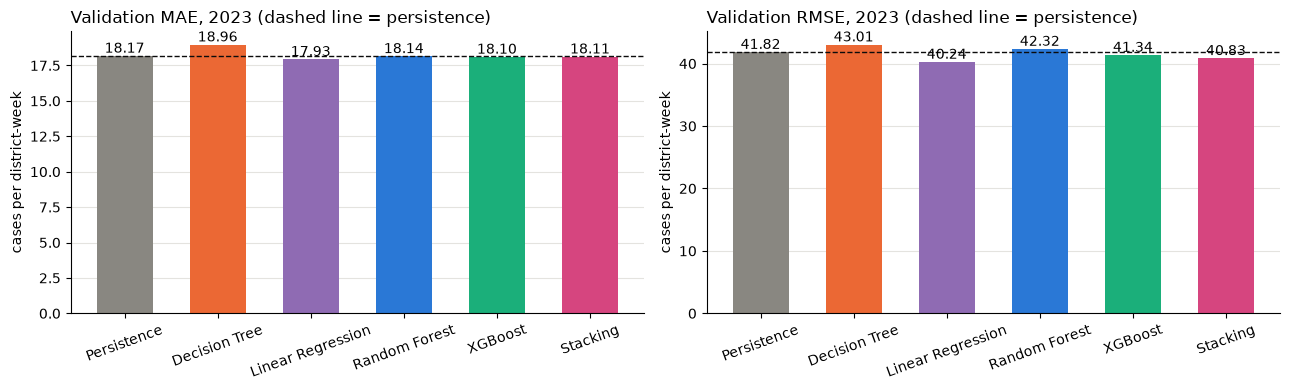

In [10]:
model_names = validation_table.index.tolist()
bar_colors = [COLORS[name] for name in model_names]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, metric in zip(axes, ["MAE", "RMSE"]):
    values = validation_table[metric].to_numpy()
    ax.bar(model_names, values, color=bar_colors, width=0.6)
    for i, v in enumerate(values):
        ax.text(i, v, f"{v:.2f}", ha="center", va="bottom")
    ax.axhline(validation_table.loc["Persistence", metric], color=INK, linewidth=1, linestyle="--")
    ax.set_title(f"Validation {metric}, 2023 (dashed line = persistence)", loc="left")
    ax.set_ylabel("cases per district-week")
    ax.tick_params(axis="x", rotation=20)
    ax.grid(axis="y", color=GRID)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**What the validation results show**

- **Stacking** (MAE 18.11, RMSE 40.83) is slightly better than persistence (-0.3% MAE, -2.4% RMSE). Its RMSE is lower than both tree ensembles' (Random Forest 42.32, XGBoost 41.34).
- **But Linear Regression on its own is the best model on 2023** (MAE 17.93, RMSE 40.24). The stack does not beat its own best base model here.
- As in notebooks 05 and 06, all models except the single Decision Tree are within about 1.5% of persistence in MAE. On a single year, differences this small are not enough to call one model better, so the test set decides.

## 8. Final test (2024-2026)

The stack is now fixed: three base models with their settings from notebooks 04-06 and the meta-model chosen on 2023.

1. **Meta-model:** refit on **all** walk-forward base predictions, 2016-2023, so it also learns from 2023.
2. **Base models:** the final Random Forest (notebook 05) and XGBoost (notebook 06) are **loaded**, so they are exactly the evaluated models. Both were trained on target weeks 2007-2023. The Linear Regression is trained on the same 2007-2023 rows here.
3. **Load the test set** (`test.csv`, target weeks 2024-2026) for the first time, with the same leakage check, and **score once** on the same 3,508 rows as notebooks 05 and 06. Nothing is changed after seeing these scores.

**Only load joblib/pickle files from a trusted source** - loading one can run code.

In [11]:
test = pd.read_csv(TEST_PATH, parse_dates=["start_date", "target_date"])

# leakage check: interpolated weeks (same rule as for the training data)
test_leaky = test["is_imputed"] | test["target_imputed"]
test = test[~test_leaky].reset_index(drop=True)
print("removed interpolated test rows:", test_leaky.sum())

# safety checks
assert data["target_date"].max() < test["target_date"].min()                       # all training weeks come first
assert test[FEATURES + [TARGET]].notna().all().all()
assert (test["target_date"] - test["start_date"] == pd.Timedelta(days=7)).all()    # target = the following week
assert len(test) == rf_info["test_rows"] == xgb_info["test_rows"]                  # same test rows as notebooks 05 and 06
assert len(data) == rf_info["final_train_rows"] == xgb_info["final_train_rows"]    # same training rows

X_test, y_test = test[FEATURES], test[TARGET].to_numpy()

# base models: two loaded, one trained on 2007-2023
final_lr = LinearRegression()
final_lr.fit(data[FEATURES], data[TARGET])
final_xgb = XGBRegressor()
final_xgb.load_model(XGB_MODEL_PATH)
final_base_models = {"Random Forest": joblib.load(RF_MODEL_PATH), "XGBoost": final_xgb, "Linear Regression": final_lr}

# meta-model: refit on the 2016-2023 base predictions
final_meta = fit_meta_model(best_meta_name, stack_data)
print("meta-model refit on", len(stack_data), "base predictions (2016-2023)")

test_base = base_predictions(final_base_models, X_test)
test_predictions = {
    "Persistence": test["current_week_cases"].to_numpy(dtype=float),
    "Linear Regression": test_base["Linear Regression"].to_numpy(),
    "Random Forest": test_base["Random Forest"].to_numpy(),
    "XGBoost": test_base["XGBoost"].to_numpy(),
    "Stacking": stack_predict(final_meta, test_base),
}

# the loaded base models must reproduce the test scores of notebooks 05 and 06
for name, info in [("Random Forest", rf_info), ("XGBoost", xgb_info)]:
    assert abs(mean_absolute_error(y_test, test_predictions[name]) - info["test_scores"][name]["MAE"]) < 0.0005
print("test rows:", len(test), "| target weeks", test["target_date"].min().date(), "to", test["target_date"].max().date())

removed interpolated test rows: 106
meta-model refit on 10816 base predictions (2016-2023)


test rows: 3508 | target weeks 2024-01-06 to 2026-08-29


In [12]:
test_results = pd.DataFrame({name: evaluate(y_test, p) for name, p in test_predictions.items()}).T
test_results["MAE vs persistence (%)"] = 100 * (test_results["MAE"] / test_results.loc["Persistence", "MAE"] - 1)
test_results["RMSE vs persistence (%)"] = 100 * (test_results["RMSE"] / test_results.loc["Persistence", "RMSE"] - 1)
test_results.round(2)

,MAE,RMSE,MAE vs persistence (%),RMSE vs persistence (%)
Persistence,12.63,29.93,0.00,0.00
Linear Regression,11.90,26.95,-5.81,-9.95
Random Forest,12.53,33.63,-0.80,12.37
XGBoost,13.22,39.19,4.63,30.94
Stacking,12.18,27.72,-3.56,-7.39


### Results by test year

2026 only runs until the end of August.

In [13]:
test_year = test["target_date"].dt.year.to_numpy()
year_rows = []
for year in sorted(np.unique(test_year)):
    rows = test_year == year
    row = {"year": int(year), "rows": int(rows.sum()), "mean weekly cases": y_test[rows].mean()}
    for name, p in test_predictions.items():
        row[f"{name} MAE"] = mean_absolute_error(y_test[rows], p[rows])
    row["Stacking MAE vs persistence (%)"] = 100 * (row["Stacking MAE"] / row["Persistence MAE"] - 1)
    year_rows.append(row)

by_year = pd.DataFrame(year_rows).set_index("year")
by_year.round(2)

,rows,mean weekly cases,Persistence MAE,Linear Regression MAE,Random Forest MAE,XGBoost MAE,Stacking MAE,Stacking MAE vs persistence (%)
year,,,,,,,,
2024,1352,37.14,10.45,9.97,9.53,9.47,10.24,-2.08
2025,1352,37.57,8.68,8.61,8.31,8.27,8.63,-0.63
2026,804,98.86,22.93,20.66,24.66,27.82,21.42,-6.56


**What the test results show**

- **Stacking beats persistence on both metrics:** MAE 12.18 vs 12.63 (**-3.6%**) and RMSE 27.72 vs 29.93 (**-7.4%**). Neither the Random Forest (RMSE +12.4%) nor XGBoost (MAE +4.6%, RMSE +30.9%) managed this.
- Stacking is also **better than both tree ensembles** overall, mainly because it handles the 2026 outbreak much better: 2026 MAE 21.42, against 24.66 (Random Forest) and 27.82 (XGBoost). In the moderate years 2024 and 2025 it is a little worse than the tree ensembles (for example 10.24 vs 9.53 and 9.47 in 2024), but still better than persistence every year.
- **However, Linear Regression on its own is the best model on the test set:** MAE 11.90 (**-5.8%**) and RMSE 26.95 (**-10.0%**), and the lowest MAE of all models in 2026 (20.66). The stack follows Linear Regression closely (section 9) but is slightly worse than it.
- This is a fair result: Linear Regression has no settings to choose, and the meta-model was chosen on 2023 before the test set was used. It is still a single test period dominated by one large outbreak, so it does not prove that a linear model is better in general.

## 9. How the stack decided

To see what a meta-model has learned, both candidates are shown, each refit on the 2016-2023 base predictions. Only the selected one is used for the stacking predictions above.

### 9.1 Linear meta-model: the weights

In [14]:
fitted_meta = {name: (final_meta if name == best_meta_name else fit_meta_model(name, stack_data)) for name in META_SETTINGS}
linear_name = "Linear Regression meta-model (positive=True)"
forest_name = "Random Forest meta-model (100 trees)"

linear_meta = fitted_meta[linear_name]
linear_weights = pd.Series(linear_meta.coef_, index=BASE_MODELS)
print("prediction = {:.2f}".format(linear_meta.intercept_)
      + "".join(f" + {w:.3f} x {name}" for name, w in linear_weights.items()))
print("sum of the weights:", round(linear_weights.sum(), 3))
linear_weights.round(3).to_frame("weight")

prediction = -0.31 + 0.000 x Random Forest + 0.034 x XGBoost + 1.007 x Linear Regression
sum of the weights: 1.041


,weight
Random Forest,0.000
XGBoost,0.034
Linear Regression,1.007


**What the linear meta-model learned**

- It puts practically **all the weight on Linear Regression** (1.007), a tiny weight on XGBoost (0.034) and **none on the Random Forest** (0.000). So the stack is, in practice, "Linear Regression, scaled up by about 4%".
- **Why:** the meta-model is fitted by least squares, so the biggest errors matter most, and the biggest errors in 2016-2023 come from the 2017 epidemic, where Linear Regression was far better than the trees (section 5). Because the Random Forest and XGBoost make almost the same errors (correlation 0.98), once XGBoost has a small weight, the Random Forest adds nothing. With `positive=True` its weight cannot go below zero, so it is set to exactly 0.

### 9.2 Random Forest meta-model: feature importance

The meta-forest's "features" are the three base predictions. Its impurity-based importance shows how much each base prediction was used in its splits.

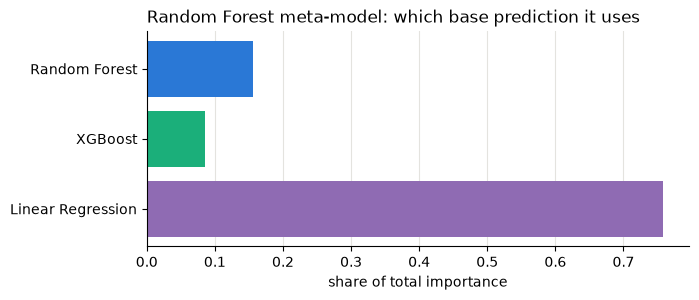

,importance
Random Forest,0.155
XGBoost,0.086
Linear Regression,0.759


In [15]:
forest_meta = fitted_meta[forest_name]
meta_importance = pd.Series(forest_meta.feature_importances_, index=BASE_MODELS)

fig, ax = plt.subplots(figsize=(7, 2.8))
ax.barh(BASE_MODELS[::-1], meta_importance[BASE_MODELS[::-1]].to_numpy(),
        color=[COLORS[name] for name in BASE_MODELS[::-1]])
ax.set_xlabel("share of total importance")
ax.set_title("Random Forest meta-model: which base prediction it uses", loc="left")
ax.grid(axis="x", color=GRID)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

meta_importance.round(3).to_frame("importance")

The Random Forest meta-model also relies mostly on the **Linear Regression** prediction (importance 0.76), with smaller shares for the Random Forest (0.16) and XGBoost (0.09). Both meta-models agree that Linear Regression is the most useful input. The forest just turns that into many yes/no rules, which overfit (section 6).

### 9.3 Example: Colombo, July 2026

The largest single error in the test period (notebook 08, section 5.5): Colombo, input week starting 2026-07-04, with 1,625 cases this week and 1,330 the next week.

In [16]:
peak = test.index[(test["district"] == "Colombo") & (test["start_date"] == "2026-07-04")]
peak_base = test_base.loc[peak]

example = {"actual next week": int(test.loc[peak, TARGET].iloc[0]),
           "persistence (this week)": int(test.loc[peak, "current_week_cases"].iloc[0])}
example.update({f"{name} (base)": round(peak_base[name].iloc[0]) for name in BASE_MODELS})
example.update({f"stack, {name}": round(stack_predict(meta, peak_base)[0]) for name, meta in fitted_meta.items()})
pd.Series(example).to_frame("cases")

,cases
actual next week,1330
persistence (this week),1625
Random Forest (base),1599
XGBoost (base),2265
Linear Regression (base),1487
"stack, Random Forest meta-model (100 trees)",1910
"stack, Linear Regression meta-model (positive=True)",1575


- The base models disagree strongly: XGBoost predicted about **2,265** (935 too many), the Random Forest about 1,599 and Linear Regression about 1,487. The actual value was **1,330**.
- The **linear stack** predicts about **1,575** (1.007 x 1,487 + 0.034 x 2,265 - 0.31). It follows Linear Regression and takes only a small part of XGBoost's overshoot. Its error (+245) is about a quarter of XGBoost's.
- The **Random Forest meta-model** would have predicted about **1,910**. Very high predictions were rare in its training rows (mostly 2017), so its yes/no rules for this range are based on only a few weeks.

## 10. Save the models and the results

- **Linear Regression base model:** `models/07_final_linear_regression_model.joblib` (trained on 2007-2023). The Random Forest and XGBoost base models are the files from notebooks 05 and 06.
- **Meta-model:** `models/07_stacking_meta_model.joblib`. It expects the three base predictions in the column order `Random Forest`, `XGBoost` (clipped at 0), `Linear Regression`, and its output is clipped at 0.
- **Results:** `models/07_stacking_results.json`: the same keys as the notebook 05 and 06 results, plus `meta_model`, `base_models` and `meta_weights`. Used by notebook 08 and the dashboard.

Both joblib files are loaded back and must give exactly the same test predictions.

In [17]:
LR_MODEL_PATH.parent.mkdir(exist_ok=True)
joblib.dump(final_lr, LR_MODEL_PATH, compress=3)
joblib.dump(final_meta, META_MODEL_PATH, compress=3)

reloaded_base = dict(final_base_models, **{"Linear Regression": joblib.load(LR_MODEL_PATH)})
reloaded_stack = stack_predict(joblib.load(META_MODEL_PATH), base_predictions(reloaded_base, X_test))
assert np.array_equal(reloaded_stack, test_predictions["Stacking"])
for path in [LR_MODEL_PATH, META_MODEL_PATH]:
    print("saved", path, f"({path.stat().st_size / 1e6:.2f} MB)")
print("reloaded models give identical predictions")

if isinstance(final_meta, LinearRegression):
    meta_weights, meta_weights_kind = dict(zip(BASE_MODELS, final_meta.coef_)), "linear weights (coefficients)"
    meta_intercept = float(final_meta.intercept_)
else:
    meta_weights, meta_weights_kind = dict(zip(BASE_MODELS, final_meta.feature_importances_)), "feature importance"
    meta_intercept = None


def to_dict(table):
    return {str(k): {c: float(v) for c, v in row.items()} for k, row in table.round(3).to_dict(orient="index").items()}


summary = {
    "created_by": "notebooks analysis/07_stacking.ipynb",
    "model": "Stacking",
    "ensemble_type": "stacking",
    "params": META_SETTINGS[best_meta_name]["params"],
    "random_state": RANDOM_STATE,
    "features": FEATURES,
    "target": TARGET,
    "validation_year": VALIDATION_YEAR,
    "removed_rows": "is_imputed or target_imputed (interpolated weeks)",
    "settings_compared": to_dict(meta_results.set_index("meta-model")),
    "validation_scores": to_dict(validation_table[["MAE", "RMSE"]]),
    "final_train_rows": int(len(data)),
    "test_rows": int(len(test)),
    "test_scores": to_dict(test_results[["MAE", "RMSE"]]),
    "library_versions": {"scikit-learn": sklearn.__version__, "xgboost": xgboost.__version__,
                         "pandas": pd.__version__, "numpy": np.__version__},
    "meta_model": best_meta_name,
    "meta_model_type": META_SETTINGS[best_meta_name]["type"],
    "base_models": BASE_MODELS,
    "base_model_files": {"Random Forest": "models/05_final_random_forest_model.joblib",
                         "XGBoost": "models/06_final_xgboost_model.json (predictions clipped at 0)",
                         "Linear Regression": "models/07_final_linear_regression_model.joblib"},
    "meta_weights": {k: round(float(v), 4) for k, v in meta_weights.items()},
    "meta_weights_kind": meta_weights_kind,
    "meta_intercept": meta_intercept,
    "meta_training_years": [FIRST_STACK_YEAR, VALIDATION_YEAR],
    "predictions_clipped_at_zero": True,
}
RESULTS_PATH.write_text(json.dumps(summary, indent=2))
print("saved", RESULTS_PATH)

saved ..\models\07_final_linear_regression_model.joblib (0.00 MB)
saved ..\models\07_stacking_meta_model.joblib (0.00 MB)
reloaded models give identical predictions
saved ..\models\07_stacking_results.json


## 11. Summary

**Stacking** = Random Forest (notebook 05) + XGBoost (notebook 06, clipped at 0) + Linear Regression, combined by a **Linear Regression meta-model with `positive=True`**. The meta-model learned from walk-forward base predictions (2016-2022 to choose it, 2016-2023 for the final fit).

**Validation (2023)** - every model trained on target weeks up to 2022

| Model | Validation MAE | Validation RMSE |
|---|---|---|
| Persistence | 18.17 | 41.82 |
| Decision Tree | 18.96 | 43.01 |
| Linear Regression | **17.93** | **40.24** |
| Random Forest | 18.14 | 42.32 |
| XGBoost | 18.10 | 41.34 |
| Stacking | 18.11 | 40.83 |

**Final test (2024-2026)** - 3,508 district-weeks

| Model | Test MAE | Test RMSE | MAE vs persistence | RMSE vs persistence |
|---|---|---|---|---|
| Persistence | 12.63 | 29.93 | - | - |
| Linear Regression | **11.90** | **26.95** | **-5.8%** | **-10.0%** |
| Random Forest | 12.53 | 33.63 | -0.8% | +12.4% |
| XGBoost | 13.22 | 39.19 | +4.6% | +30.9% |
| Stacking | 12.18 | 27.72 | -3.6% | -7.4% |

**Key points**
1. **Stacking needs base models that make different mistakes.** The Random Forest and XGBoost are almost identical in their errors (correlation 0.98); Linear Regression is the different one (about 0.62).
2. **The meta-model learned to trust Linear Regression** (weight 1.007; XGBoost 0.034; Random Forest 0). Linear Regression handled the 2017 epidemic far better, because trees cannot predict beyond the counts they have seen.
3. **A simple meta-model is better:** the Random Forest meta-model overfitted (2023 MAE 19.88).
4. **On the test years, stacking beats persistence on both MAE and RMSE and beats both tree ensembles**, mainly thanks to the 2026 outbreak. But it does **not** beat Linear Regression alone, which was the best model on the test set.
5. Fair evaluation: walk-forward base predictions (no future weeks), meta-model chosen on 2023, test set used once.

**Saved:** `models/07_final_linear_regression_model.joblib`, `models/07_stacking_meta_model.joblib`, `models/07_stacking_results.json`.

**Next:** notebook 08 compares bagging, boosting and stacking on the same test rows and looks at why they differ.